# Laboratory: Exploring Pretrained Models on Hugging Face

**Intelligent Agents — UC3. Intelligent Agents with Generative Models**
**3.2 Language Models as Agents: LLMs as Reasoners**

---

### Objectives
By the end of this lab you will be able to:
- Find, inspect and load pretrained models from the Hugging Face Hub.
- Use the `pipeline()` function to solve NLP tasks **out of the box** (no training).
- Run three guided tasks: **text summarization**, **translation (English → Japanese)** and **zero-shot classification**.
- Choose and implement a pretrained model for a **task of your own choice**.
- Analyze model outputs and their limitations.

### Lab structure
| Part | Task | What you do |
|---|---|---|
| 0 | Background & environment setup | Read + run |
| 1 | Text summarization | Run, then modify |
| 2 | Translation EN → JA | Run, then compare models |
| 3 | Zero-shot classification | Run, then propose your own case |
| 4 | Open task | Choose a model and implement it yourself |

### Running this notebook in Google Colab
1. Go to <https://colab.research.google.com> → **File → Upload notebook** and pick this `.ipynb` file (or open it from Google Drive with *Open with → Google Colaboratory*).
2. Turn on the GPU: **Runtime → Change runtime type → Hardware accelerator: T4 GPU → Save**. (Everything also runs on CPU, only more slowly.)
3. Run **Part 0.1** first. If it restarts the runtime, that is expected: just continue with the next cell.
4. Run the cells **in order** from top to bottom (`Shift + Enter`). If you get lost, use **Runtime → Run all** after the setup cell.

## Part 0 — Pretrained open models on Hugging Face

### What is a pretrained model?
A **pretrained model** is a neural network whose weights were already learned on a large dataset for a specific task (summarizing news, translating, classifying, answering questions…). Most of these models are **specialists**: very good at one narrow job. You can:
1. **Use them out of the box** (this lab),
2. **Fine-tune** them on your own data, or
3. Train a similar model from scratch (expensive, rarely needed).

For many production problems a small specialized model is the right choice: calling a large general-purpose LLM for a simple task increases **cost** and **latency** without necessarily improving quality.

### The Hugging Face Hub
[Hugging Face](https://huggingface.co) is an AI company and open-source platform. Its **Hub** hosts more than one million models, plus datasets and demo apps ("Spaces"). Most NLP models there are based on the **Transformer** architecture.

How to find a model at <https://huggingface.co/models>:
1. **Select the task** in the left panel (e.g. *Summarization*) — this acts as a filter.
2. **Filter by name** or sort by *Trending*, *Most downloads*, *Most likes*.
3. Open the **model card** and read it.

### What to look at on a model card
| Section | Why it matters |
|---|---|
| **Model card** (left) | How to use the model, training data, benchmark metrics, intended uses and limitations |
| **Inference widget** (right) | Try the model in the browser before downloading anything |
| **Files and versions** | Size of the weights → memory/disk needed for deployment |
| **Community** | Discussions, issues, history of the model |
| **License** | Whether you may use it commercially (e.g. Apache-2.0, MIT, CC-BY-NC…) |
| **Tags** | Framework (PyTorch / TF / JAX), language(s), datasets |

### The `pipeline()` function
The `transformers` library provides `pipeline()`, a one-line interface that bundles the three steps of every inference:

```
raw text ──► tokenizer ──► model ──► post-processing ──► readable output
```

```python
from transformers import pipeline
my_pipe = pipeline(task="summarization", model="sshleifer/distilbart-cnn-12-6")
my_pipe("some long text ...")
```

The first time you create a pipeline, the model files (config, tokenizer, weights) are **downloaded** and cached locally (by default in `~/.cache/huggingface`). Later runs reuse the cache.

## 0.1 Environment setup

Google Colab already ships with `torch`, `pandas` and `matplotlib`, so we only add what is missing:

| Package | Used for |
|---|---|
| `transformers` (4.x) | `pipeline()` and the models |
| `sentencepiece`, `sacremoses` | Tokenizers required by translation models |
| `langchain-community`, `arxiv`, `pymupdf` | Download and read an Arxiv paper as text |

> **Why the automatic restart?** This lab uses the `summarization` and `translation` pipeline tasks of `transformers` **4.x**. If Colab has a different major version pre-installed, the cell installs 4.x and then **restarts the runtime** so Python loads the new version. You will see a *"Your session crashed / restarted"* message — that is intended. After the restart, **do not run this cell again**; continue with the next cell (0.2).

In [ ]:
#%% 0.1 Install packages (run once per Colab session; ~1–2 minutes)
import os, importlib.metadata as metadata

# Packages that Colab does not include by default
!pip install -q sentencepiece sacremoses langchain-community arxiv pymupdf

# Make sure transformers 4.x is installed (needed for the summarization/translation pipelines)
try:
    tf_version = metadata.version("transformers")
except metadata.PackageNotFoundError:
    tf_version = "none"
print("transformers found:", tf_version)

if not tf_version.startswith("4."):
    !pip install -q "transformers>=4.45,<5"
    print("\n✅ transformers 4.x installed. The runtime will now RESTART.")
    print("👉 After the restart, continue with the NEXT cell (do not run this one again).")
    os.kill(os.getpid(), 9)      # restarts the Colab runtime
else:
    print("✅ Environment ready — no restart needed.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
transformers found: 5.22.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 0.2 Check versions and hardware
If the output says **CPU**, enable the GPU (*Runtime → Change runtime type → T4 GPU*) and run Part 0.1 again.

In [1]:
#%% 0.2 Check versions and hardware
import sys, torch, transformers

print("Python       :", sys.version.split()[0])
print("transformers :", transformers.__version__)
print("torch        :", torch.__version__)

DEVICE = 0 if torch.cuda.is_available() else -1   # 0 = first GPU, -1 = CPU
print("Running on   :", torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU")

Python       : 3.13.16
transformers : 4.57.6
torch        : 2.14.1+cu130
Running on   : Tesla T4


### (Optional) Hugging Face token
Public models can be downloaded without an account, but you may see a warning such as *"The secret `HF_TOKEN` does not exist"*. It is safe to ignore. A token gives higher download rate limits and is required for *gated* models (e.g. some Llama models).

To use one in Colab:
1. Create a **Read** token at <https://huggingface.co/settings/tokens>.
2. In Colab, click the 🔑 **Secrets** icon in the left sidebar → **Add new secret** → name `HF_TOKEN`, value = your token → switch on **Notebook access**.
3. Run the cell below. Never paste the token directly into the notebook.

In [3]:
#%% 0.3 (Optional) Use your Hugging Face token from Colab Secrets
try:
    from google.colab import userdata
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    print("✅ HF_TOKEN loaded from Colab Secrets.")
except Exception:
    print("ℹ️ No HF_TOKEN found — continuing anonymously (public models still work).")

ℹ️ No HF_TOKEN found — continuing anonymously (public models still work).


### Helper: free GPU memory between parts
Each part loads a model of 0.1–1.6 GB. The free Colab GPU has ~15 GB, which is enough, but it is good practice to release models you no longer need. We will call this helper at the end of each part.

In [4]:
#%% 0.4 Helper to release memory
import gc, torch

def free_memory(*names):
    # Delete the given global variables and empty the GPU cache
    for n in names:
        globals().pop(n, None)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        print(f"GPU memory in use: {torch.cuda.memory_allocated() / 1e9:.2f} GB")
    else:
        print("Memory released.")

---
## Part 1 — Text Summarization

### The task
**Summarization** produces a shorter text that keeps the key information of a longer one. There are two families:
- **Extractive**: copies the most important sentences.
- **Abstractive**: writes *new* sentences (what the model below does).

### The model: `sshleifer/distilbart-cnn-12-6`
Model card: <https://huggingface.co/sshleifer/distilbart-cnn-12-6>

- **Architecture:** BART, an *encoder–decoder* (sequence-to-sequence) Transformer. The encoder reads the input text; the decoder generates the summary token by token.
- **"distil":** a *distilled* (compressed) version of `facebook/bart-large-cnn`. It keeps all **12 encoder layers** but only **6 decoder layers** (hence `12-6`), so it is faster with a small loss in quality (≈306 M parameters, ≈1.2 GB of weights).
- **Training data:** CNN / DailyMail news articles with their human-written highlights → it produces **news-style** summaries.
- **Context window:** at most **1024 tokens** of input. Longer texts must be truncated or split into chunks.
- **License:** Apache-2.0.

### The data: an Arxiv paper
[Arxiv](https://arxiv.org) is an open-access archive of more than 2 million scholarly articles. LangChain's `ArxivLoader` searches Arxiv, downloads the PDF and returns it as a list of `Document` objects. Each `Document` has `metadata` (title, authors, date…) and `page_content` (the full text).

### 1.1 Create the summarizer
`pipeline()` needs a **task** and a **model name**; it returns a ready-to-use summarizer object.

In [5]:
#%% packages
import torch
from transformers import pipeline
from langchain_community.document_loaders import ArxivLoader

DEVICE = 0 if torch.cuda.is_available() else -1

#%% model selection
task = "summarization"
model = "sshleifer/distilbart-cnn-12-6"
summarizer = pipeline(task=task, model=model, device=DEVICE)

/tmp/ipykernel_1516/1149486734.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import ArxivLoader


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

Device set to use cuda:0


### 1.2 Load an Arxiv article
We search for papers about **"prompt engineering"** and keep only the first result (`load_max_docs=1`). Calling `.load()` actually downloads and parses the PDF.

> Arxiv sometimes rate-limits requests coming from Colab. If the download fails, the cell uses a short **fallback text** so you can still continue with the lab (try again later to use a real paper).

In [8]:
### Data Preparation
import arxiv
import fitz  # PyMuPDF
import io
import requests

query = "prompt engineering"

try:
    # Initialize the modern arxiv client
    client = arxiv.Client()
    search = arxiv.Search(
        query=query,
        max_results=1,
        sort_by=arxiv.SortCriterion.Relevance
    )

    # Fetch results
    results = list(client.results(search))
    if len(results) > 0:
        paper = results[0]
        print("Documents loaded: 1")
        print("Metadata        :", {
            "Title": paper.title,
            "Published": paper.published.strftime("%Y-%m-%d"),
            "Authors": [author.name for author in paper.authors],
            "Summary": paper.summary
        })

        # Directly download the PDF bytes using requests
        print("Downloading PDF...")
        pdf_response = requests.get(paper.pdf_url)
        pdf_response.raise_for_status()
        pdf_file = io.BytesIO(pdf_response.content)

        # Extract text using PyMuPDF (fitz)
        doc = fitz.open(stream=pdf_file, filetype="pdf")
        article_text = "".join([page.get_text() for page in doc])
        print(f"\nSuccessfully extracted {len(article_text)} characters from the downloaded paper.")
    else:
        raise ValueError("No papers found on Arxiv for the query.")

except Exception as e:
    print("⚠️ Could not download from Arxiv:", type(e).__name__, e)
    print("Using the fallback text instead.")
    article_text = (
        "Prompt engineering is the practice of designing the inputs given to large language "
        "models so that they produce useful, accurate and safe outputs. Because modern models "
        "are trained on very large text collections and then adapted to follow instructions, "
        "their behaviour depends strongly on how a request is phrased. Small changes in wording, "
        "in the order of examples, or in the format requested can change the quality of the "
        "answer considerably. Common techniques include giving clear instructions, providing a "
        "few worked examples (few-shot prompting), asking the model to reason step by step "
        "(chain-of-thought prompting), assigning the model a role, and specifying the expected "
        "output format. More advanced approaches let the model call external tools, retrieve "
        "documents before answering, or critique and revise its own drafts. These ideas are the "
        "foundation of LLM-based agents, which combine a language model with memory, tools and a "
        "control loop. However, prompts are fragile: a prompt that works well for one model may "
        "fail for another, and evaluation remains difficult because outputs are open-ended. "
        "Researchers therefore study systematic methods to design, test and automatically "
        "optimize prompts, and to understand why certain prompts work."
    )

Documents loaded: 1
Metadata        : {'Title': 'TDD Governance for Multi-Agent Code Generation via Prompt Engineering', 'Published': '2026-04-29', 'Authors': ['Tarlan Hasanli', 'Shahbaz Siddeeq', 'Bishwash Khanal', 'Pyry Kotilainen', 'Tommi Mikkonen', 'Pekka Abrahamsson'], 'Summary': 'Large language models (LLMs) accelerate software development but often exhibit instability, non-determinism, and weak adherence to development discipline in unconstrained workflows. While test-driven development (TDD) provides a structured Red-Green-Refactor process, existing LLM-based approaches typically use tests as auxiliary inputs rather than enforceable process constraints. We present an AI-native TDD framework that operationalizes classical TDD principles as structured prompt-level and workflow-level governance mechanisms. Extracted principles are formalized in a machine-readable manifesto and distributed across planning, generation, repair, and validation stages within a layered architecture that

In [9]:
#%% Inspect the article text
print("Total characters in the article:", len(article_text))
print("\n--- First 800 characters ---\n")
print(article_text[:800])

Total characters in the article: 31638

--- First 800 characters ---

TDD Governance for Multi-Agent Code Generation via Prompt
Engineering
Tarlan Hasanli∗
tarlan.h.hasanli@jyu.fi
University of Jyväskylä
Jyväskylä, Finland
Shahbaz Siddeeq∗
shahbaz.siddeeq@tuni.fi
Tampere University
Tampere, Finland
Bishwash Khanal
bishwash.b.khanal@jyu.fi
University of Jyväskylä
Jyväskylä, Finland
Pyry Kotilainen
pyry.kotilainen@jyu.fi
University of Jyväskylä
Jyväskylä, Finland
Tommi Mikkonen
tommi.j.mikkonen@jyu.fi
University of Jyväskylä
Jyväskylä, Finland
Pekka Abrahamsson
pekka.abrahamsson@tuni.fi
Tampere University
Tampere, Finland
Abstract
Large language models (LLMs) accelerate software development
but often exhibit instability, non-determinism, and weak adher-
ence to development discipline in unconstrained workflows. While
test-driven development (TDD) provides a st


### 1.3 Summarize
We cannot pass the full article because of the model's context window, so we use only the **first 2,000 characters** (roughly the title + abstract + start of the introduction).

Generation parameters:
- `min_length`, `max_length` – bounds for the summary length, measured in **tokens** (not words).
- `do_sample=False` – deterministic output: the model always chooses the most likely tokens, so you get the same summary every run.

The result is a **list with one dictionary**: `[{'summary_text': '...'}]`.

In [10]:
#%% Summarize the first 2,000 characters
result = summarizer(article_text[:2000], min_length=20, max_length=80, do_sample=False)

summary = result[0]["summary_text"]
print("SUMMARY:\n", summary)

#%% number of words in the summary
print("\nTotal words:", len(summary.split(" ")))

SUMMARY:
  Large language models (LLMs) accelerate software development but often exhibit instability, non-determinism, and weak adher-centricence to development discipline in unconstrained workflows . TDD Governance for Multi-Agent Code Generation via Prompt Engineering, Software Engineering Governance.

Total words: 35


### 1.4 (Extension) Summarizing a longer text by chunks
A common workaround for the context limit is **map-reduce summarization**: split the text into chunks, summarize each chunk, then join (or re-summarize) the partial summaries.

In [11]:
#%% Chunked summarization of the first ~8,000 characters
def chunk_text(text, chunk_size=2000):
    return [text[i:i + chunk_size] for i in range(0, len(text), chunk_size)]

chunks = chunk_text(article_text[:8000])
partial = summarizer(chunks, min_length=20, max_length=60, do_sample=False)

for i, p in enumerate(partial, 1):
    print(f"Chunk {i}: {p['summary_text']}\n")

combined = " ".join(p["summary_text"] for p in partial)
final = summarizer(combined, min_length=30, max_length=100, do_sample=False)
print("FINAL SUMMARY:\n", final[0]["summary_text"])

Chunk 1:  Large language models (LLMs) accelerate software development but often exhibit instability, non-determinism, and weak adher-centricence to development discipline in unconstrained workflows . TDD Governance for Multi-Agent Code Generation via Prompt Engineering, Software Engineering Governance.

Chunk 2:  The discipline of software engineering is undergoing a major shift toward autonomous LLM-based agents taking on complex coding tasks . In agentic AI, role-specific agents collaborate to achieve pro-programming goals with limited human intervention . In multi-agent engineering, small logic errors can spread

Chunk 3:  This paper presents a prompt-centric multi-agent framework that turns TDD principles into enforceable rules for LLM-based code generation . Specialized agents follow explicit guidance, and an orchestrator controls phase order and checks test outcomes before transitions . By embedding TDD into

Chunk 4:  Repository-scale analysis shows that LLMs produce incorrect 

### ✏️ Your turn (Part 1)
1. Change `query` to a topic you like (e.g. `"reinforcement learning agents"`) and summarize the new paper.
2. Try different `min_length` / `max_length` values. What happens when `min_length` is too high?
3. Set `do_sample=True` and run the cell several times. Does the summary change? Why?
4. Read the summary critically: is every statement actually supported by the original text? Write down any **hallucination** or omission you find.

In [12]:
#%% Release the summarizer before moving on
free_memory("summarizer")

GPU memory in use: 1.23 GB


---
## Part 2 — Translation (English → Japanese)

### The task
**Machine translation** converts text from a source language to a target language. In the guide you were asked to find a suitable model yourself; here is a worked solution, followed by a comparison exercise.

How to find a model on the Hub: *Models → Natural Language Processing → **Translation*** and filter by language (*Languages: English, Japanese*) or search `en-ja`.

### The model: `Mitsua/elan-mt-bt-en-ja`
Model card: <https://huggingface.co/Mitsua/elan-mt-bt-en-ja>

- **Architecture:** **Marian** encoder–decoder Transformer (the same family as the well-known `Helsinki-NLP/opus-mt-*` models), specialized in **one direction** only: English → Japanese.
- **Small:** about 60 M parameters (≈121 MB of weights), so it downloads quickly and runs well even on CPU.
- **"bt":** trained with **back-translation**, a data-augmentation technique in which synthetic sentence pairs are generated by translating in the opposite direction.
- **Tokenizer:** SentencePiece (`source.spm`), which is why we installed `sentencepiece`. You may see a warning recommending `sacremoses` — it is installed.

In [13]:
#%% packages
import torch
from transformers import pipeline
DEVICE = 0 if torch.cuda.is_available() else -1

#%% model selection
task = "translation"
model = "Mitsua/elan-mt-bt-en-ja"
translator = pipeline(task=task, model=model, device=DEVICE)

#%% translate
text = "Be the change you wish to see in the world."
result = translator(text)
print(result[0]["translation_text"])

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/121M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/304 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/854 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/793k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/439 [00:00<?, ?B/s]

Device set to use cuda:0


世の中の見たい変化になれ。


The output should be similar to **世の中の見たい変化になれ。** (literally: *"Become the change you want to see in the world."*).

The pipeline also accepts a **list** of sentences, which is more efficient than calling it once per sentence:

In [14]:
#%% translate a batch of sentences
sentences = [
    "Be the change you wish to see in the world.",
    "Intelligent agents perceive their environment and act to achieve their goals.",
    "Pretrained models can be used without any additional training.",
    "It's raining cats and dogs.",          # idiom: will it be translated literally?
]

for src, out in zip(sentences, translator(sentences)):
    print(f"EN: {src}\nJA: {out['translation_text']}\n")

EN: Be the change you wish to see in the world.
JA: 世の中の見たい変化になれ。

EN: Intelligent agents perceive their environment and act to achieve their goals.
JA: 知的なエージェントは環境を認識し、目標を達成するために行動する。

EN: Pretrained models can be used without any additional training.
JA: 事前学習済みモデルは、追加のトレーニングなしで使用できる。

EN: It's raining cats and dogs.
JA: 雨が激しく降っている。



### 2.1 (Extension) Comparing with a multilingual model
`facebook/nllb-200-distilled-600M` (*No Language Left Behind*) is a **single** model that translates between 200 languages. Because it is multilingual, you must tell it the source and target languages with FLORES-200 codes (`eng_Latn` → `jpn_Jpan`). It is larger (≈600 M parameters, ≈2.5 GB) and its license is **CC-BY-NC** (non-commercial).

In [15]:
#%% (Optional) multilingual model — larger download
nllb = pipeline(
    task="translation",
    model="facebook/nllb-200-distilled-600M",
    src_lang="eng_Latn",
    tgt_lang="jpn_Jpan",
    device=DEVICE,
)

for src, out in zip(sentences, nllb(sentences)):
    print(f"EN: {src}\nJA: {out['translation_text']}\n")

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/2.46G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.46G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/4.85M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.3M [00:00<?, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0


EN: Be the change you wish to see in the world.
JA: 世界で見たい変化になれ

EN: Intelligent agents perceive their environment and act to achieve their goals.
JA: 知的なエージェントは環境を認識し 目標を達成するために行動します

EN: Pretrained models can be used without any additional training.
JA: 予備訓練を受けたモデルは,追加訓練なしに使用できます.

EN: It's raining cats and dogs.
JA: 猫と犬の雨が降っている.



### ✏️ Your turn (Part 2)
1. Compare both models in a small table: download size, speed, and translation of the idiom.
2. Translate the Japanese output **back to English** with a JA → EN model (search the Hub, e.g. `Mitsua/elan-mt-bt-ja-en`). Is the meaning preserved? (This is called *round-trip translation*.)
3. Change the NLLB `tgt_lang` to Spanish (`spa_Latn`) or Kichwa/Quechua (`quy_Latn`). What does this tell you about the advantage of multilingual models?

In [16]:
#%% Release the translation models before moving on
free_memory("translator", "nllb")

GPU memory in use: 1.23 GB


---
## Part 3 — Zero-shot Classification

### The task
**Zero-shot classification** assigns a text to categories the model was **never explicitly trained on**. You simply provide a list of **candidate labels** at inference time, and the model returns a probability for each one. No labeled examples are needed, which makes it very useful when new categories appear frequently.

### The model: `facebook/bart-large-mnli`
Model card: <https://huggingface.co/facebook/bart-large-mnli>

- **Architecture:** BART-large (≈400 M parameters, ≈1.6 GB) fine-tuned on **MNLI** (*Multi-Genre Natural Language Inference*).
- **NLI task:** given a **premise** and a **hypothesis**, decide whether the hypothesis is *entailed*, *neutral* or *contradicted* by the premise.
- **The trick that makes zero-shot possible:** each candidate label is turned into a hypothesis:

  | Premise (your text) | Hypothesis (built from a label) |
  |---|---|
  | "Alice was beginning to get very tired…" | "This example is **fantasy**." |
  | "Alice was beginning to get very tired…" | "This example is **crime**." |

  The **entailment** probability of each hypothesis becomes that label's score. By default the scores are normalized with a softmax so that they sum to 1.

### Our experiment
We take the opening lines of three classic (public-domain) books that clearly belong to different genres — **romance**, **fantasy** and **crime** — and check whether the classifier can guess the genre from those few sentences alone.

In [17]:
#%% packages
import torch
from transformers import pipeline
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
DEVICE = 0 if torch.cuda.is_available() else -1

#%% Classifier
classifier = pipeline(task="zero-shot-classification",
                      model="facebook/bart-large-mnli",
                      device=DEVICE)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0


In [19]:
#%% Data Preparation
# 1) Jane Austen: Pride and Prejudice              (romantic novel)
# 2) Lewis Carroll: Alice's Adventures in Wonderland (fantasy novel)
# 3) Arthur Conan Doyle: The Return of Sherlock Holmes (crime novel)
titles = ["Pride and Prejudice",
          "Alice's Adventures in Wonderland",
          "The Return of Sherlock Holmes"]

documents = [
    "It is a truth universally acknowledged, that a single man in possession of a good "
    "fortune, must be in want of a wife. However little known the feelings or views of such "
    "a man may be on his first entering a neighbourhood, this truth is so well fixed in the "
    "minds of the surrounding families, that he is considered the rightful property of some "
    "one or other of their daughters.",

    "Alice was beginning to get very tired of sitting by her sister on the bank, and of having "
    "nothing to do: once or twice she had peeped into the book her sister was reading, but it "
    "had no pictures or conversations in it, 'and what is the use of a book,' thought Alice "
    "'without pictures or conversations?' So she was considering in her own mind (as well as "
    "she could, for the hot day made her feel very sleepy and stupid), whether the pleasure of "
    "making a daisy-chain would be worth the trouble of getting up and picking the daisies, "
    "when suddenly a White Rabbit with pink eyes ran close by her.",

    "It was in the spring of the year 1894 that all London was interested, and the fashionable "
    "world dismayed, by the murder of the Honourable Ronald Adair under most unusual and "
    "inexplicable circumstances. The public has already learned those particulars of the crime "
    "which came out in the police investigation, but a good deal was suppressed upon that "
    "occasion, since the case for the prosecution was so overwhelmingly strong that it was not "
    "necessary to bring forward all the facts.",
]

candidate_labels = ["romance", "fantasy", "crime"]

### 3.1 Classify
The pipeline returns, for each document, a dictionary with the input `sequence`, the `labels` **sorted from most to least likely**, and their `scores`.

In [20]:
#%% classify documents
res = classifier(documents, candidate_labels=candidate_labels)

for title, r in zip(titles, res):
    print(f"{title:35s} → predicted: {r['labels'][0]:8s} (score = {r['scores'][0]:.3f})")

Pride and Prejudice                 → predicted: romance  (score = 0.627)
Alice's Adventures in Wonderland    → predicted: romance  (score = 0.457)
The Return of Sherlock Holmes       → predicted: crime    (score = 0.954)


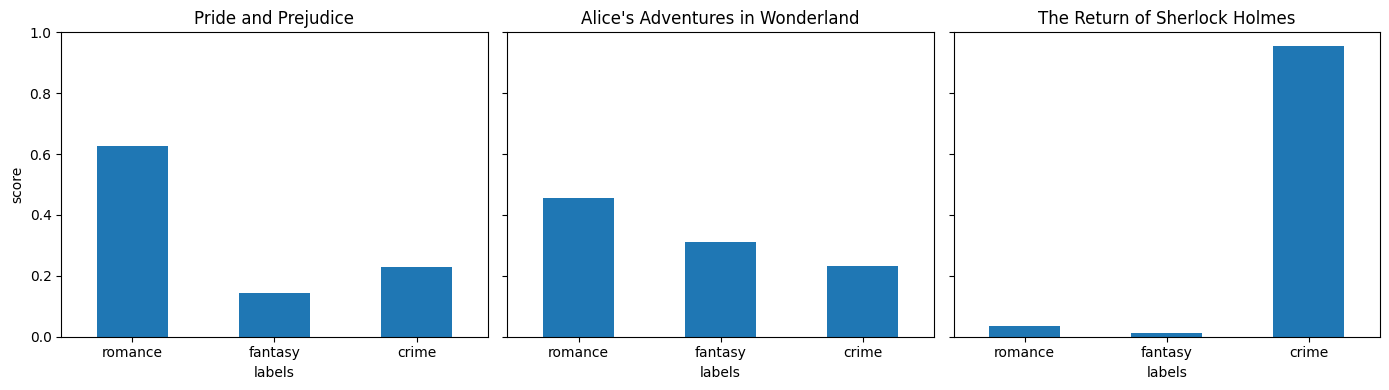

In [21]:
#%% visualize results (one bar chart per book)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for ax, title, r in zip(axes, titles, res):
    df = pd.DataFrame({"labels": r["labels"], "scores": r["scores"]})
    df = df.set_index("labels").loc[candidate_labels]      # same label order in every plot
    df.plot.bar(ax=ax, legend=False, rot=0)
    ax.set_title(title)
    ax.set_ylabel("score")
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

### 3.2 Two useful options
- **`hypothesis_template`** – changes the sentence built from each label. A template that matches your domain often improves accuracy.
- **`multi_label=True`** – scores each label **independently** (they no longer sum to 1). Use it when a text can belong to several categories at once.

In [22]:
#%% custom hypothesis template + multi-label
res_ml = classifier(
    documents,
    candidate_labels=["romance", "fantasy", "crime", "humor", "mystery", "marriage"],
    hypothesis_template="The genre of this book is {}.",
    multi_label=True,
)

pd.DataFrame(
    {t: dict(zip(r["labels"], r["scores"])) for t, r in zip(titles, res_ml)}
).round(3)

,Pride and Prejudice,Alice's Adventures in Wonderland,The Return of Sherlock Holmes
marriage,0.203,0.101,0.005
romance,0.089,0.228,0.046
mystery,0.084,0.396,0.783
crime,0.055,0.074,0.945
humor,0.035,0.086,0.022
fantasy,0.024,0.517,0.105


### ✏️ Your turn (Part 3) — propose your own zero-shot case
Design and run **your own** zero-shot classification example. Some ideas:
- Customer support tickets → `["billing", "technical problem", "account access", "feedback"]`
- News headlines → `["politics", "sports", "science", "economy"]`
- Student questions in a course forum → `["deadline", "grading", "concept doubt", "technical issue"]`
- Tweets/reviews → `["positive", "negative", "neutral"]`

Requirements:
1. At least **5 texts** and **3–6 labels**.
2. Write down the label you *expect* for each text **before** running the model, and report the **accuracy**.
3. Try two different `hypothesis_template`s and compare.
4. Find at least one example where the model fails and explain why you think it failed.

In [ ]:
#%% YOUR zero-shot case
my_texts = [
    # "text 1",
    # "text 2",
]
my_labels = [
    # "label A", "label B", "label C",
]
my_expected = [
    # "label A", ...
]

# my_res = classifier(my_texts, candidate_labels=my_labels)
# predicted = [r["labels"][0] for r in my_res]
# accuracy = sum(p == e for p, e in zip(predicted, my_expected)) / len(my_expected)
# print("Accuracy:", accuracy)

---
## Part 4 — Open Task: choose your own pretrained model

Now apply the full workflow on your own: **understand the task → find a suitable model on the Hub → read its model card → implement it → evaluate it critically.**

The task must be **different** from the three above. Suggestions (all available as `pipeline()` tasks):

| Task (`pipeline` name) | Example use | Example models to start your search |
|---|---|---|
| `sentiment-analysis` / `text-classification` | Product review polarity, emotion detection | `cardiffnlp/twitter-roberta-base-sentiment-latest`, `j-hartmann/emotion-english-distilroberta-base` |
| `ner` (token classification) | Extract people, places, organizations | `dslim/bert-base-NER` |
| `question-answering` | Answer a question from a given paragraph | `deepset/roberta-base-squad2` |
| `fill-mask` | Predict a missing word; probe model knowledge/bias | `bert-base-uncased`, `xlm-roberta-base` |
| `text-generation` | Continue a prompt; test simple reasoning | `Qwen/Qwen2.5-0.5B-Instruct`, `gpt2` |
| `image-classification` | Classify a photo | `google/vit-base-patch16-224` |
| `image-to-text` | Caption an image | `Salesforce/blip-image-captioning-base` |
| `automatic-speech-recognition` | Transcribe audio | `openai/whisper-tiny` |
| `zero-shot-image-classification` | Classify images with free-text labels | `openai/clip-vit-base-patch32` |

> You may choose a task not in this list. Keep the model **small** (< ~2 GB) so it runs on the free Colab GPU.
>
> **Images or audio in Colab:** upload a file with the 📁 **Files** icon in the left sidebar (it appears under `/content/`), or pass a public URL directly to the pipeline, e.g. `my_pipe("https://.../photo.jpg")`. Run `free_memory("classifier")` first if you are short on GPU memory.

### Deliverables (fill in the cells below)
1. **Task description** – what problem you solve and why it is useful.
2. **Model selection** – model name, link, architecture, size, training data, license, and why you chose it over alternatives.
3. **Implementation** – working code using `pipeline()` (or `AutoModel…` classes if needed).
4. **Experiments** – at least **5 different inputs**, including at least one "hard" or tricky input.
5. **Analysis** – where the model succeeds, where it fails, and what limitations you observed (bias, language coverage, context length, hallucinations, logical errors…).

### 4.1 Task description
*(Write here)*

### 4.2 Model selection
| Item | Your answer |
|---|---|
| Model name & link | |
| Task / pipeline name | |
| Architecture | |
| Size (parameters / GB) | |
| Training data | |
| License | |
| Why this model? | |

In [ ]:
#%% 4.3 Implementation
import torch
from transformers import pipeline
DEVICE = 0 if torch.cuda.is_available() else -1

my_task  = ""     # e.g. "question-answering"
my_model = ""     # e.g. "deepset/roberta-base-squad2"

# my_pipe = pipeline(task=my_task, model=my_model, device=DEVICE)

In [ ]:
#%% 4.4 Experiments (at least 5 inputs, including a tricky one)
my_inputs = [
    # ...
]

# for x in my_inputs:
#     print(x, "→", my_pipe(x), "\n")

### 4.5 Analysis
*(Write here: successes, failures, limitations, and what you would try next — e.g. a bigger model, fine-tuning, or a general-purpose LLM.)*

---
## Final reflection questions
Answer briefly (3–5 lines each):

1. All the models used today are **specialists**. In which situations would you prefer one of them over a general-purpose LLM, and when would you choose the LLM? Consider cost, latency, privacy and quality.
2. The summarizer only saw the first 2,000 characters. How can this lead to a misleading summary of the whole paper?
3. The zero-shot classifier reasons through **natural language inference**. Give an example of a text where the entailment logic could produce a wrong label (e.g. negation: *"This is not a crime story."*). Test it.
4. If you wanted to build an **intelligent agent** that reads papers, translates them and sorts them by topic, how could you chain the three pipelines from this lab together? Sketch the agent's perceive → decide → act loop.

In [ ]:
#%% Space to test your negation example for question 3
# classifier("This is not a crime story; it is a gentle love story.", candidate_labels=["romance", "crime"])

---
## References
- Gollnick, B. (2025). *Generative AI with Python: The Developer's Guide to Pretrained LLMs, Vector Databases, Retrieval-Augmented Generation, and Agentic Systems*. Rheinwerk Publishing. Code: <https://github.com/DataScienceHamburg/GenerativeAiApplicationsWithPython_Material>
- Hugging Face Hub: <https://huggingface.co> · Transformers docs: <https://huggingface.co/docs/transformers/index>
- Summarization task: <https://huggingface.co/tasks/summarization> · DistilBART: <https://huggingface.co/sshleifer/distilbart-cnn-12-6>
- Text summarization with DistilBART: <https://machinelearningmastery.com/text-summarization-with-distillbart-model/>
- ElanMT EN→JA: <https://huggingface.co/Mitsua/elan-mt-bt-en-ja> · NLLB-200: <https://huggingface.co/facebook/nllb-200-distilled-600M>
- BART-large-MNLI: <https://huggingface.co/facebook/bart-large-mnli>
- Arxiv: <https://arxiv.org> · LangChain: <https://www.langchain.com/langchain>